# Predicting bondline thickness out-of-spec risk
## A reproducible synthetic display-lamination capstone

**All records are synthetic.** No proprietary factory records, commercial recipes, or real production performance are represented.

### Research question
Can information available before a lot starts identify whether its measured mean bondline thickness will fall outside its product-specific limits?

**Success criterion** — At least 80% recall with a false-positive rate no greater than 15% on a later, untouched test period.

An early warning could help operations prioritize inspection and investigate equipment conditions before processing a lot. This study tests that workflow in a simulator. Actual yield improvements and financial savings require a factory trial.

### Scope and decision
There are 30,000 units in 600 lots of 50 units, processed by six fictional tools over 100 days. One prediction is made per lot, immediately before production. The primary target is `lot_bondline_oos`, defined by the measured lot mean. An acceptable lot mean can coexist with individual units outside the same limits. Individual-unit rejection and spatial uniformity are separate quality questions.

The [README](README.md) contains the nontechnical report, and the [data dictionary](DATA_DICTIONARY.md) defines every exported field. Run cells in order from the extracted project folder.

In [21]:
from pathlib import Path
import os
import sys
import json
import hashlib
import tempfile
import platform
import importlib.metadata

ROOT = Path.cwd()
assert (ROOT / 'generate_data.py').exists(), 'Start Jupyter in the extracted project folder.'
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'lamination_mpl'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                            recall_score, f1_score, confusion_matrix,
                            precision_recall_curve, roc_curve)
from sklearn.inspection import permutation_importance
from generate_data import write_dataset, FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET, SEED

RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False,
                     'font.size':10, 'axes.titlesize':12})
BLUE, RED, GREEN = '#236A8B', '#BD4848', '#347A5B'
environment = {'python': platform.python_version()}
for package in ['numpy','pandas','scipy','scikit-learn','matplotlib','nbformat','nbclient','ipykernel']:
    environment[package] = importlib.metadata.version(package)
(RESULTS / 'environment.json').write_text(json.dumps(environment, indent=2) + '\n')
display(pd.Series(environment, name='Executed environment'))

python          3.9.13
numpy           1.21.5
pandas           1.4.4
scipy            1.9.1
scikit-learn     1.0.2
matplotlib       3.5.2
nbformat         5.5.0
nbclient        0.5.13
ipykernel       6.15.2
Name: Executed environment, dtype: object

## 1. Reproduce the data and audit provenance

The seed is fixed at 20261106. The notebook independently regenerates the three data tables into a temporary folder and checks their SHA-256 hashes against the supplied manifest. If the data folder is absent, it generates it first. Data generation and model evaluation use independent random-number generators.

The simulator uses product-specific nominal optical adhesive thicknesses of 150 and 175 µm, with compressed bondline centers of 142 and 167 µm. Both lot-mean specifications have a ±7.5 µm tolerance. These are fictional study assumptions. Stabilization checks cover approximately 23–42 °C, 0.09–0.22 MPa pressure, and 5–100 Pa absolute vacuum. Higher absolute vacuum pressure means poorer evacuation.

The process combines incoming material variation, pressure and temperature effects, tool offsets, correlated drift, wear accumulation, scheduled maintenance resets, occasional hidden shocks, five-site spatial variation, and measurement noise. A material distribution shift begins on day 72. About 1.2% of values in four precheck fields are missing independently of quality. History is unavailable for each tool's first lot.

3M's public OCA guidance provides context for vacuum and lamination pressure scales. The generator's coefficients, geometry, limits, and maintenance schedule are analyst assumptions. See the [technical resource](https://multimedia.3m.com/mws/media/1775425O/3m-optically-clear-adhesive-oca-817x-series.pdf).

In [22]:
DATA = ROOT / 'data'
if not (DATA / 'manifest.json').exists():
    write_dataset(DATA)
manifest = json.loads((DATA / 'manifest.json').read_text())
with tempfile.TemporaryDirectory() as temporary:
    reproduced = write_dataset(Path(temporary))
    assert reproduced['sha256'] == manifest['sha256'], 'Regeneration mismatch.'
for filename, expected in manifest['sha256'].items():
    assert hashlib.sha256((DATA / filename).read_bytes()).hexdigest() == expected

lot_dates = ['prediction_time_utc','precheck_time_utc','metrology_available_at_utc',
             'history_latest_available_at_utc']
lots = pd.read_csv(DATA / 'lamination_lots.csv', parse_dates=lot_dates)
units = pd.read_csv(DATA / 'lamination_units.csv',
                    parse_dates=['production_time_utc','metrology_available_at_utc'])
maintenance = pd.read_csv(DATA / 'maintenance_events.csv', parse_dates=['maintenance_time_utc'])
lots = lots.sort_values('prediction_time_utc').reset_index(drop=True)
assert len(units) == 30000 and len(lots) == 600
assert lots.tool_id.nunique() == 6 and units.unit_id.is_unique and lots.lot_id.is_unique
assert units.groupby('lot_id').size().eq(50).all()
assert set(units.lot_id) == set(lots.lot_id)
assert lots.is_synthetic.all() and units.is_synthetic.all()
recomputed = units.groupby('lot_id').unit_mean_bondline_um.mean().reindex(lots.lot_id).to_numpy()
np.testing.assert_allclose(recomputed, lots.lot_mean_bondline_um, atol=1e-6)
expected_target = ((recomputed < lots.spec_lower_um) | (recomputed > lots.spec_upper_um)).astype(int)
np.testing.assert_array_equal(expected_target, lots[TARGET])
assert (lots.precheck_time_utc < lots.prediction_time_utc).all()
assert (lots.metrology_available_at_utc > lots.prediction_time_utc).all()
known = lots.history_latest_available_at_utc.notna()
assert (lots.loc[known,'history_latest_available_at_utc'] < lots.loc[known,'prediction_time_utc']).all()
# Independently reconstruct history using released prior metrology only.
for _, row in lots.iterrows():
    prior = lots[(lots.tool_id == row.tool_id) &
                 (lots.metrology_available_at_utc < row.prediction_time_utc)].tail(3)
    assert len(prior) == row.history_count
    if len(prior):
        np.testing.assert_allclose((prior.lot_mean_bondline_um-prior.target_bondline_um).mean(),
                                  row.historical_mean_delta_um, atol=1.1e-6)
        np.testing.assert_allclose(prior[TARGET].mean(), row.historical_oos_rate, atol=1e-6)
        assert prior.metrology_available_at_utc.max() == row.history_latest_available_at_utc
assert len(FEATURES) == len(set(FEATURES))
assert not set(FEATURES) & {TARGET,'lot_id','lot_mean_bondline_um','metrology_available_at_utc'}
print('Verified 30,000 units, 600 complete lots, six tools, labels, precheck timing, and causal history.')
print('Independent data regeneration and all three file hashes match.')

Verified 30,000 units, 600 complete lots, six tools, labels, precheck timing, and causal history.
Independent data regeneration and all three file hashes match.


## 2. Lock the chronological evaluation plan

The first 60 days train the models, the next 20 days select the operating threshold, and the final 20 days provide the test. All six tools are present in every period. The experiment measures future-lot performance on the same tools.

Four expanding-window folds use training days only. Each validation window spans ten days, with a full day excluded between fitting and validation. This exceeds the 170-minute metrology reporting delay. Pipeline imputation, scaling, and encoding are fitted separately within each fold. Model family and hyperparameters are selected by mean validation average precision, which summarizes the precision–recall tradeoff under class imbalance.

The threshold is selected on days 60–79 only. It maximizes recall subject to a false-positive rate at most 15%. Ties favor fewer false alarms and then a higher threshold. The test stays untouched until this choice is frozen.

Historical measurements update as each prior lot's inspection becomes available, including during threshold and test periods. Model weights and threshold stay fixed. This represents sequential online scoring with a working inspection feed. A forecast made for all 20 test days at once would require different history features.

In [23]:
train = lots[lots.days_since_start < 60].copy().reset_index(drop=True)
tune = lots[lots.days_since_start.between(60,79)].copy().reset_index(drop=True)
test = lots[lots.days_since_start >= 80].copy().reset_index(drop=True)
assert set(train.lot_id).isdisjoint(tune.lot_id)
assert set(train.lot_id).isdisjoint(test.lot_id)
assert set(tune.lot_id).isdisjoint(test.lot_id)
assert train.metrology_available_at_utc.max() < tune.prediction_time_utc.min()
assert tune.metrology_available_at_utc.max() < test.prediction_time_utc.min()

cv = []
fold_rows = []
training_days = np.sort(train.days_since_start.unique())
for fold, (fit_days, validation_days) in enumerate(
        TimeSeriesSplit(n_splits=4, test_size=10, gap=1).split(training_days), start=1):
    fit_index = np.flatnonzero(train.days_since_start.isin(training_days[fit_days]))
    validation_index = np.flatnonzero(train.days_since_start.isin(training_days[validation_days]))
    fit, validation = train.iloc[fit_index], train.iloc[validation_index]
    assert fit.metrology_available_at_utc.max() < validation.prediction_time_utc.min()
    assert set(fit.lot_id).isdisjoint(validation.lot_id)
    assert fit[TARGET].nunique() == validation[TARGET].nunique() == 2
    cv.append((fit_index, validation_index))
    fold_rows.append(dict(fold=fold, train_lots=len(fit), validation_lots=len(validation),
                          train_first_day=int(fit.days_since_start.min()),
                          train_last_day=int(fit.days_since_start.max()),
                          last_train_label_release=fit.metrology_available_at_utc.max(),
                          validation_first_prediction=validation.prediction_time_utc.min(),
                          validation_last_day=int(validation.days_since_start.max()),
                          validation_oos_lots=int(validation[TARGET].sum())))
fold_audit = pd.DataFrame(fold_rows)
fold_audit.to_csv(RESULTS / 'temporal_fold_audit.csv', index=False)
split_manifest = lots[['lot_id','prediction_time_utc','days_since_start']].copy()
split_manifest['split'] = np.select([lots.days_since_start < 60, lots.days_since_start < 80],
                                    ['train','threshold'], default='test')
split_manifest.to_csv(RESULTS / 'split_manifest.csv', index=False)
display(fold_audit)
print('Train / threshold / test lot counts', len(train), len(tune), len(test))

,fold,train_lots,validation_lots,train_first_day,train_last_day,last_train_label_release,validation_first_prediction,validation_last_day,validation_oos_lots
0,1,114,60,0,18,2026-01-23 16:20:00+00:00,2026-01-25 06:00:00+00:00,29,8
1,2,174,60,0,28,2026-02-02 16:20:00+00:00,2026-02-04 06:00:00+00:00,39,5
2,3,234,60,0,38,2026-02-12 16:20:00+00:00,2026-02-14 06:00:00+00:00,49,9
3,4,294,60,0,48,2026-02-22 16:20:00+00:00,2026-02-24 06:00:00+00:00,59,10


Train / threshold / test lot counts 360 120 120


## 3. Clean and explore the training period

EDA uses the training period. Complete lots and unique unit identifiers were verified above. Missing precheck values are retained for pipeline imputation, which uses fitting data medians and adds missing-value indicators. No target-conditioned deletion, outlier trimming, or class resampling is performed. Plausible excursions remain available to the models.

Thickness is normalized against each product's design center for comparison. Historical thickness is similarly normalized before averaging across product types. Charts of simulated drift and maintenance are descriptive associations.

,incoming_oca_delta_um,incoming_oca_sd_um,glass_bow_um,precheck_temperature_c,precheck_pressure_mpa,precheck_vacuum_pa_abs,precheck_roller_force_n,recipe_speed_mm_s,recipe_dwell_s,ambient_humidity_pct,cycles_since_maintenance,tool_operating_hours,historical_mean_delta_um,historical_oos_rate,history_count,history_age_hours,days_since_start
count,360.00,360.00,360.00,357.00,360.00,356.00,356.00,360.00,360.00,357.00,360.00,360.00,354.00,354.00,360.00,354.00,360.00
mean,-0.11,1.17,11.72,30.96,0.15,38.90,297.10,13.90,12.04,46.19,460.00,1660.45,1.64,0.16,2.90,21.17,29.50
std,3.32,0.32,3.93,2.13,0.01,9.09,18.20,2.48,1.31,5.97,294.77,307.99,3.65,0.24,0.47,0.00,17.34
min,-10.27,0.61,1.00,25.49,0.10,21.63,245.29,8.00,8.18,32.11,0.00,1200.00,-11.58,0.00,0.00,21.17,0.00
25%,-2.40,0.88,9.15,29.55,0.14,31.18,284.41,12.29,11.17,41.73,200.00,1390.39,-0.72,0.00,3.00,21.17,14.75
50%,-0.14,1.18,11.86,31.01,0.15,38.98,297.46,13.94,12.08,46.82,450.00,1660.45,1.73,0.00,3.00,21.17,29.50
75%,2.09,1.46,14.24,32.63,0.16,46.03,308.91,15.48,12.97,50.69,700.00,1930.38,4.17,0.33,3.00,21.17,44.25
max,9.12,1.69,22.51,36.92,0.19,58.64,344.27,22.00,16.42,60.96,1100.00,2121.09,12.51,1.00,3.00,21.17,59.00


,Missing training values
history_age_hours,6
historical_oos_rate,6
historical_mean_delta_um,6
precheck_vacuum_pa_abs,4
precheck_roller_force_n,4
ambient_humidity_pct,3
precheck_temperature_c,3


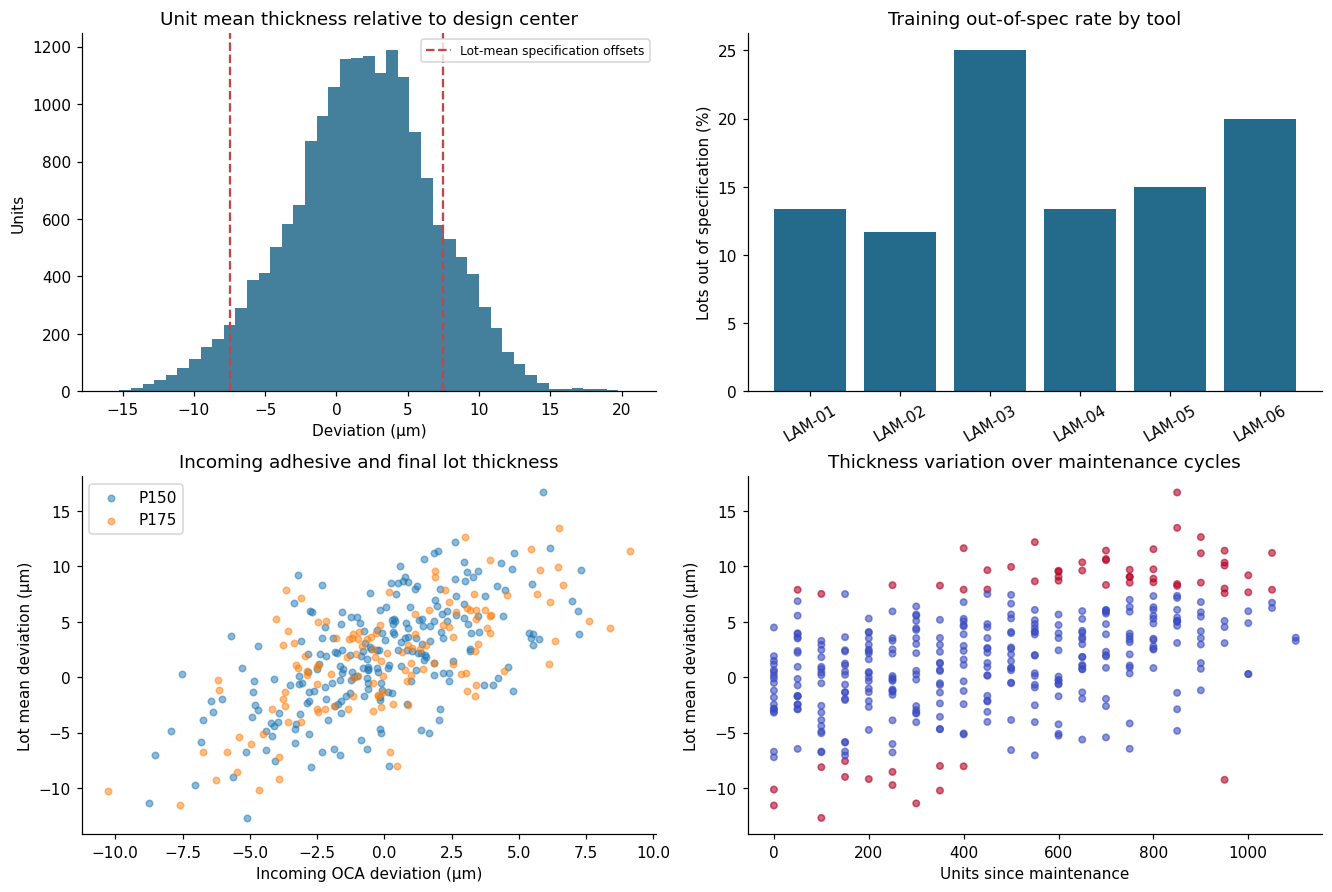

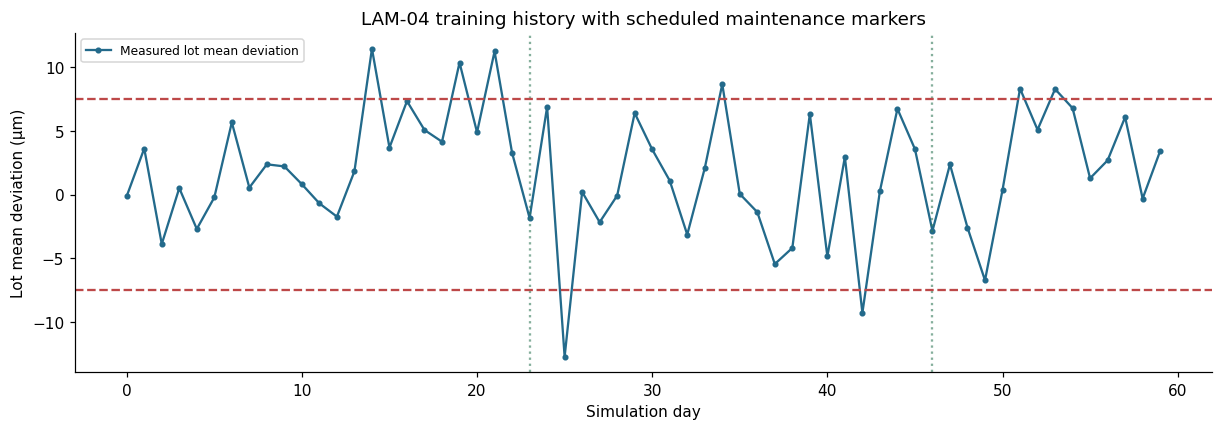

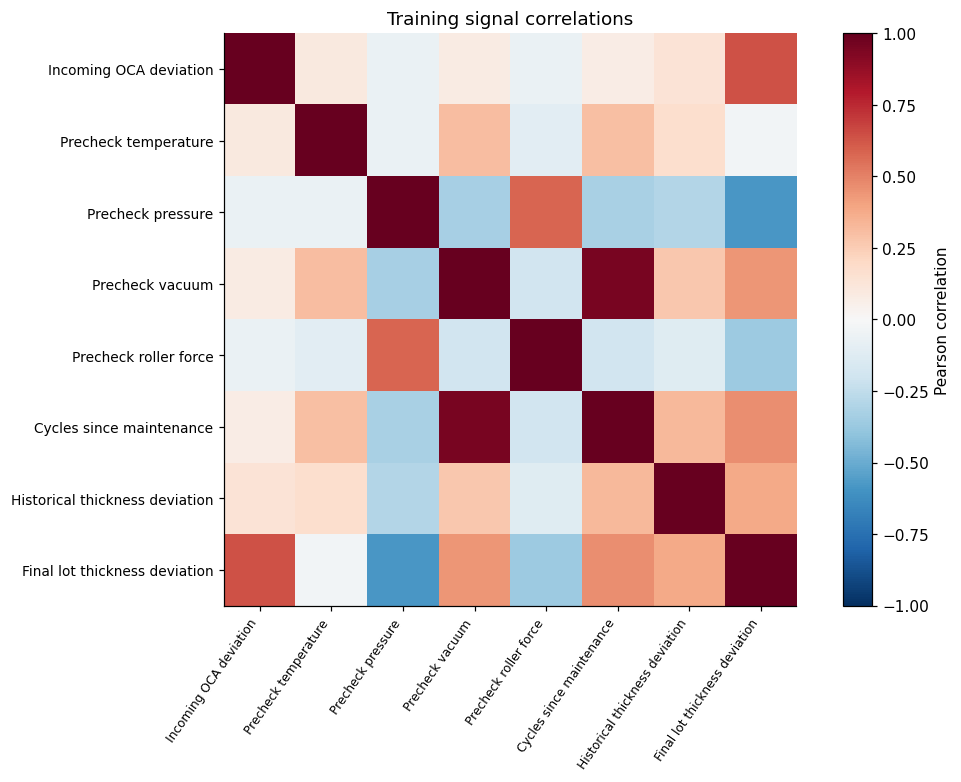

In [24]:
training_units = units[units.lot_id.isin(train.lot_id)].merge(
    train[['lot_id','target_bondline_um']], on='lot_id', validate='many_to_one')
training_units['bondline_delta_um'] = (training_units.unit_mean_bondline_um -
                                      training_units.target_bondline_um)
missing = train[FEATURES].isna().sum().sort_values(ascending=False)
display(train[NUMERIC_FEATURES].describe().round(2))
display(missing[missing > 0].rename('Missing training values').to_frame())
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes[0,0].hist(training_units.bondline_delta_um, bins=45, color=BLUE, alpha=0.85)
axes[0,0].axvline(-7.5, color=RED, linestyle='--')
axes[0,0].axvline(7.5, color=RED, linestyle='--', label='Lot-mean specification offsets')
axes[0,0].set(title='Unit mean thickness relative to design center', xlabel='Deviation (µm)', ylabel='Units')
axes[0,0].legend(fontsize=8)
rate = train.groupby('tool_id')[TARGET].mean()
axes[0,1].bar(rate.index, rate.values*100, color=BLUE)
axes[0,1].set(title='Training out-of-spec rate by tool', ylabel='Lots out of specification (%)')
axes[0,1].tick_params(axis='x', rotation=30)
for product, frame in train.groupby('product_type'):
    axes[1,0].scatter(frame.incoming_oca_delta_um, frame.lot_mean_bondline_um-frame.target_bondline_um,
                      s=18, alpha=0.5, label=product)
axes[1,0].set(title='Incoming adhesive and final lot thickness', xlabel='Incoming OCA deviation (µm)',
              ylabel='Lot mean deviation (µm)')
axes[1,0].legend()
axes[1,1].scatter(train.cycles_since_maintenance,
                   train.lot_mean_bondline_um-train.target_bondline_um,
                   c=train[TARGET], cmap='coolwarm', alpha=0.6, s=18)
axes[1,1].set(title='Thickness variation over maintenance cycles', xlabel='Units since maintenance',
              ylabel='Lot mean deviation (µm)')
fig.savefig(FIGURES/'training_overview.png', dpi=160)
plt.show()

selected = train[train.tool_id == 'LAM-04']
fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
ax.plot(selected.days_since_start, selected.lot_mean_bondline_um-selected.target_bondline_um,
        marker='o', markersize=3, color=BLUE, label='Measured lot mean deviation')
for event in maintenance[(maintenance.tool_id == 'LAM-04') &
                          (maintenance.maintenance_time_utc < tune.prediction_time_utc.min())].itertuples():
    event_day = (event.maintenance_time_utc.normalize()-lots.prediction_time_utc.min().normalize()).days
    ax.axvline(event_day, color=GREEN, alpha=0.6, linestyle=':')
ax.axhline(7.5, color=RED, linestyle='--')
ax.axhline(-7.5, color=RED, linestyle='--')
ax.set(title='LAM-04 training history with scheduled maintenance markers',
       xlabel='Simulation day', ylabel='Lot mean deviation (µm)')
ax.legend(loc='upper left', fontsize=8)
fig.savefig(FIGURES/'maintenance_history.png', dpi=160)
plt.show()

correlation_columns = ['incoming_oca_delta_um','precheck_temperature_c','precheck_pressure_mpa',
                       'precheck_vacuum_pa_abs','precheck_roller_force_n','cycles_since_maintenance',
                       'historical_mean_delta_um']
correlations = train[correlation_columns].copy()
correlations['lot_mean_delta_um'] = train.lot_mean_bondline_um-train.target_bondline_um
correlations = correlations.corr()
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
heatmap = ax.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
labels = ['Incoming OCA deviation','Precheck temperature','Precheck pressure','Precheck vacuum',
          'Precheck roller force','Cycles since maintenance','Historical thickness deviation',
          'Final lot thickness deviation']
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=55, ha='right', fontsize=8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=9)
ax.set_title('Training signal correlations')
fig.colorbar(heatmap, ax=ax, label='Pearson correlation')
fig.savefig(FIGURES/'training_correlations.png', dpi=160)
plt.show()

### What the simulator is designed to express

Thicker incoming adhesive raises final thickness. Greater pressure, force, temperature, and dwell tend to reduce thickness within the modeled range. Faster motion reduces compression. Wear and poor evacuation contribute nonlinear shifts, while scheduled maintenance reduces wear and partially resets hidden drift. These directions and strengths are encoded assumptions in `generate_data.py`.

A positive or negative thickness shift can cause out-of-spec status. This two-sided target can be difficult for a linear classifier. Tool and incoming-material differences also create a reason to compare tree-based models. Correlated pressure and roller force can share predictive information.

## 4. Baseline, classifiers, and grid search

We compare a majority-class dummy baseline, logistic regression, a decision tree, and a random forest. The dummy's constant probabilities establish an average-precision baseline at the event prevalence. Its default hard decision generally misses rare out-of-spec lots, illustrating why accuracy alone is insufficient.

Recall measures the fraction of out-of-spec lots flagged. Precision measures how many flagged lots actually exceed the limits. The false-positive rate divides false alarms by acceptable lots. Average precision is used for model selection. F1 and ROC AUC are supplementary diagnostics. Class weighting is tuned as a training choice. Reported scores are risk rankings, with no probability calibration claim.

,model,cv_average_precision,cv_fold_sd,candidates
3,Random forest,0.432,0.216,8
2,Decision tree,0.322,0.206,12
1,Logistic regression,0.274,0.082,6
0,Majority baseline,0.133,0.036,1


Logistic regression       {'model__C': 0.1, 'model__class_weight': None}
Decision tree          {'model__class_weight': 'balanced', 'model__ma...
Random forest          {'model__class_weight': 'balanced', 'model__ma...
Name: Best grid parameters, dtype: object

Selected by training-only temporal CV Random forest


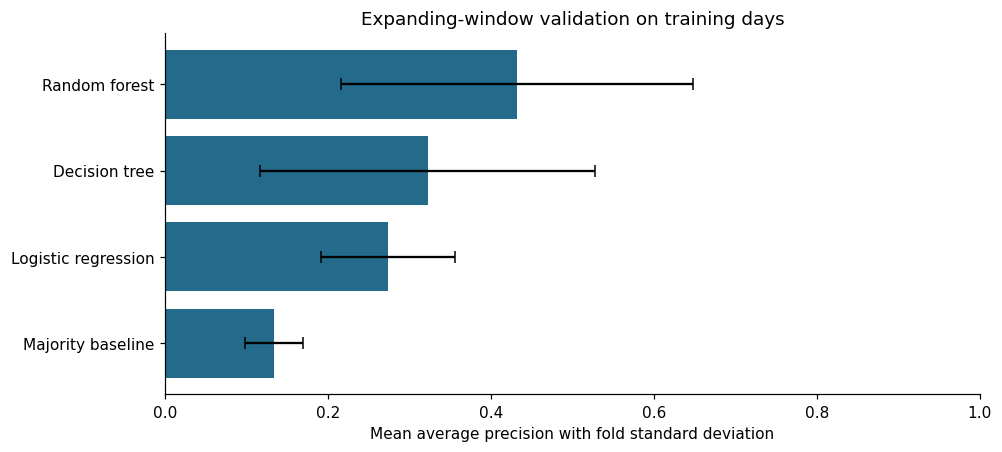

In [25]:
numeric = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                    ('scaler', StandardScaler())])
categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                        ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('numeric', numeric, NUMERIC_FEATURES),
                                 ('categorical', categorical, CATEGORICAL_FEATURES)])
X_train, y_train = train[FEATURES], train[TARGET]
X_tune, y_tune = tune[FEATURES], tune[TARGET]
models = {
    'Logistic regression': (LogisticRegression(max_iter=3000, random_state=SEED),
                            {'model__C':[0.1,1,10], 'model__class_weight':[None,'balanced']}),
    'Decision tree': (DecisionTreeClassifier(random_state=SEED),
                      {'model__max_depth':[3,6,None], 'model__min_samples_leaf':[5,15],
                       'model__class_weight':[None,'balanced']}),
    'Random forest': (RandomForestClassifier(n_estimators=160, random_state=SEED, n_jobs=1),
                      {'model__max_depth':[5,None], 'model__min_samples_leaf':[2,6],
                       'model__max_features':[0.7,1.0], 'model__class_weight':['balanced']})
}
dummy = Pipeline([('preprocess',clone(preprocessor)), ('model',DummyClassifier(strategy='prior'))])
dummy_scores = cross_val_score(dummy, X_train, y_train, cv=cv, scoring='average_precision', n_jobs=1)
searches = {}
comparison_rows = [dict(model='Majority baseline', cv_average_precision=dummy_scores.mean(),
                        cv_fold_sd=dummy_scores.std(ddof=1), candidates=1)]
grid_tables = []
for name, (estimator, parameters) in models.items():
    pipeline = Pipeline([('preprocess',clone(preprocessor)), ('model',estimator)])
    search = GridSearchCV(pipeline, parameters, cv=cv, scoring='average_precision',
                          n_jobs=1, refit=True, error_score='raise', return_train_score=False)
    search.fit(X_train, y_train)
    searches[name] = search
    best = search.best_index_
    fold_scores = [search.cv_results_[f'split{i}_test_score'][best] for i in range(len(cv))]
    comparison_rows.append(dict(model=name, cv_average_precision=search.best_score_,
                                cv_fold_sd=np.std(fold_scores, ddof=1),
                                candidates=len(search.cv_results_['params'])))
    table = pd.DataFrame(search.cv_results_)
    table.insert(0,'model',name)
    grid_tables.append(table)
comparison = pd.DataFrame(comparison_rows).sort_values('cv_average_precision', ascending=False)
comparison.to_csv(RESULTS/'model_comparison_cv.csv', index=False)
pd.concat(grid_tables, ignore_index=True).to_csv(RESULTS/'grid_search_results.csv', index=False)
winner_name = max(searches, key=lambda name: searches[name].best_score_)
winner = searches[winner_name].best_estimator_
best_parameters = {name: search.best_params_ for name, search in searches.items()}
display(comparison.round(3))
display(pd.Series(best_parameters, name='Best grid parameters'))
print('Selected by training-only temporal CV', winner_name)
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.barh(comparison.model[::-1], comparison.cv_average_precision[::-1], color=BLUE,
        xerr=comparison.cv_fold_sd[::-1], capsize=4)
ax.set(xlabel='Mean average precision with fold standard deviation',
       title='Expanding-window validation on training days', xlim=(0,1))
fig.savefig(FIGURES/'model_comparison.png', dpi=160)
plt.show()

## 5. Select the alert threshold using the middle period

The selected classifier is already fitted using training days only. It is held fixed while the threshold is selected. Neither this model nor its threshold is refitted after seeing the final test results. If the threshold period cannot achieve both desired operating metrics, the shortfall is retained in the report.

,Threshold-period operating point
threshold,0.413696
recall,0.900000
false_positive_rate,0.140000
precision,0.562500
tn,86.000000
fp,14.000000
fn,2.000000
tp,18.000000


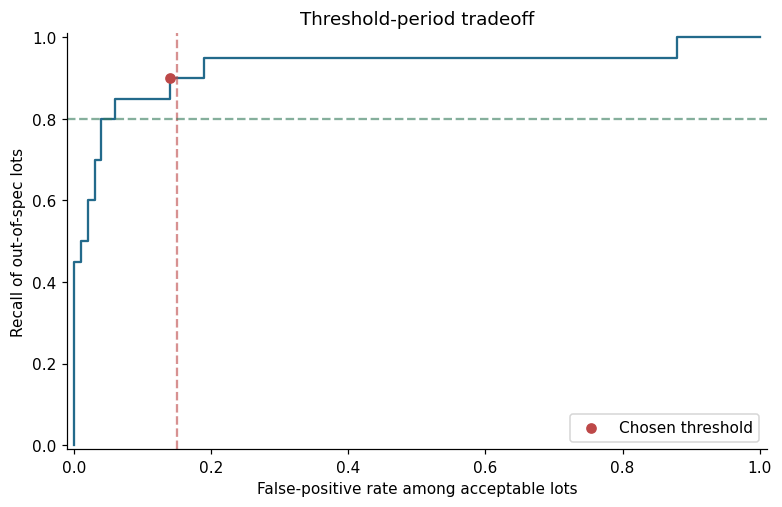

In [26]:
tune_probability = winner.predict_proba(X_tune)[:,1]
threshold_rows = []
for threshold in np.r_[np.unique(tune_probability), np.nextafter(tune_probability.max(), np.inf)]:
    prediction = (tune_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_tune, prediction, labels=[0,1]).ravel()
    threshold_rows.append(dict(threshold=float(threshold), recall=tp/(tp+fn),
                               false_positive_rate=fp/(fp+tn),
                               precision=precision_score(y_tune,prediction,zero_division=0),
                               tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp)))
threshold_table = pd.DataFrame(threshold_rows)
feasible = threshold_table[threshold_table.false_positive_rate <= 0.15]
choice = feasible.sort_values(['recall','false_positive_rate','threshold'],
                             ascending=[False,True,False]).iloc[0]
threshold = float(choice.threshold)
threshold_table.to_csv(RESULTS/'threshold_selection.csv', index=False)
frozen_choice = {'model':winner_name,'threshold':threshold,
                 'best_parameters':best_parameters[winner_name],
                 'feature_columns':FEATURES,'fit_days':[0,59],
                 'threshold_days':[60,79],'test_days':[80,99]}
(RESULTS/'frozen_model_choice.json').write_text(json.dumps(frozen_choice,indent=2)+'\n')
display(choice.to_frame('Threshold-period operating point'))
fig, ax = plt.subplots(figsize=(7,4.5), constrained_layout=True)
ax.plot(threshold_table.false_positive_rate,threshold_table.recall, color=BLUE)
ax.scatter(choice.false_positive_rate,choice.recall,color=RED,zorder=3,label='Chosen threshold')
ax.axvline(0.15,color=RED,linestyle='--',alpha=0.6)
ax.axhline(0.80,color=GREEN,linestyle='--',alpha=0.6)
ax.set(xlabel='False-positive rate among acceptable lots',ylabel='Recall of out-of-spec lots',
       title='Threshold-period tradeoff',xlim=(-0.01,1.01),ylim=(-0.01,1.01))
ax.legend()
fig.savefig(FIGURES/'threshold_tradeoff.png',dpi=160)
plt.show()

## 6. Evaluate once on the final 20 days

This section opens the test outcomes. The selected model and threshold are frozen. The comparison below includes default 0.5 thresholds for the classifiers and the chosen threshold for the winner. Test comparisons are descriptive and do not change the selected model. Subgroups with no out-of-spec lots have undefined recall and average precision, shown as blank values.

There are only 120 test lots. The uncertainty analysis resamples contiguous five-day blocks, preserving each day's six-tool grouping and short-range dependence within blocks. The resulting intervals describe uncertainty within this synthetic run. Four available blocks provide limited support for longer-range dependence or real-world inference.

,model,threshold,precision,recall,f1,false_positive_rate,average_precision,roc_auc,tn,fp,fn,tp
0,Majority baseline,0.500,0.000,0.000,0.000,0.000,0.100,0.500,108,0,12,0
1,Logistic regression (default),0.500,1.000,0.167,0.286,0.000,0.508,0.814,108,0,10,2
2,Decision tree (default),0.500,0.207,0.500,0.293,0.213,0.237,0.663,85,23,6,6
3,Random forest (default),0.500,0.312,0.417,0.357,0.102,0.505,0.856,97,11,7,5
4,Random forest (selected threshold),0.414,0.286,0.667,0.400,0.185,0.505,0.856,88,20,4,8


,lower_95,upper_95
recall,0.400,0.900
false_positive_rate,0.133,0.243
precision,0.120,0.385
average_precision,0.295,0.837


Success criterion not met


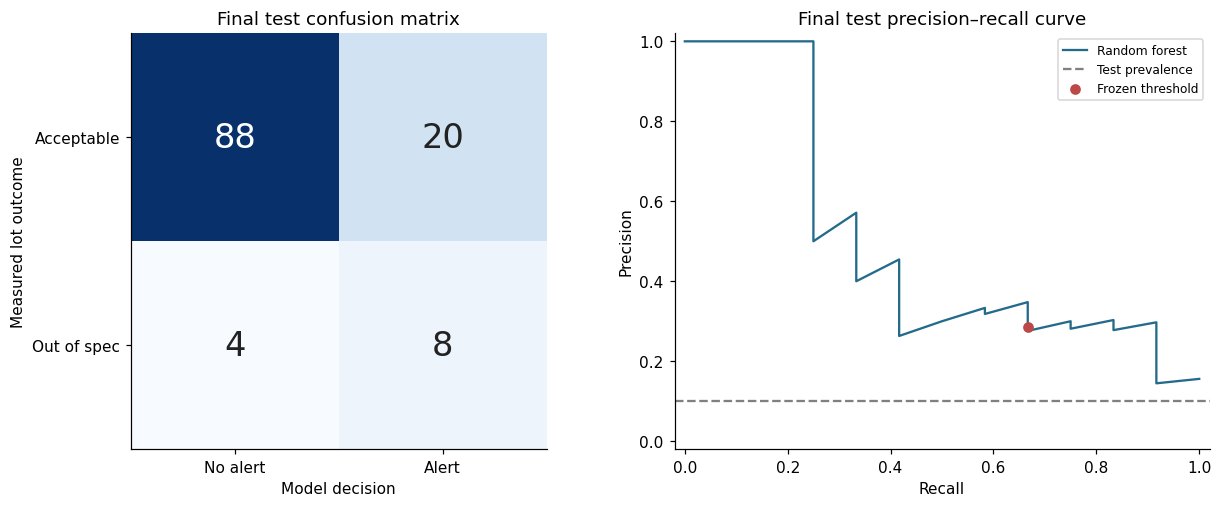

,group_type,group,lots,oos_lots,recall,false_positive_rate
0,tool_id,LAM-01,20,1,0.00,0.105
1,tool_id,LAM-02,20,1,1.00,0.263
2,tool_id,LAM-03,20,0,NaN,0.200
3,tool_id,LAM-04,20,3,1.00,0.059
4,tool_id,LAM-05,20,2,1.00,0.167
5,tool_id,LAM-06,20,5,0.40,0.333
6,product_type,P150,72,8,0.75,0.203
7,product_type,P175,48,4,0.50,0.159


In [27]:
def metrics(y, probability, cutoff):
    prediction = (probability >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y,prediction,labels=[0,1]).ravel()
    return dict(precision=precision_score(y,prediction,zero_division=0),
                recall=recall_score(y,prediction,zero_division=0) if np.asarray(y).sum() else np.nan,
                f1=f1_score(y,prediction,zero_division=0),
                false_positive_rate=fp/(fp+tn) if fp+tn else np.nan,
                average_precision=average_precision_score(y,probability) if np.asarray(y).sum() else np.nan,
                roc_auc=roc_auc_score(y,probability) if len(np.unique(y))==2 else np.nan,
                tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

X_test, y_test = test[FEATURES], test[TARGET]
probability = winner.predict_proba(X_test)[:,1]
prediction = (probability >= threshold).astype(int)
result = metrics(y_test, probability, threshold)
dummy.fit(X_train,y_train)
rows = [dict(model='Majority baseline',threshold=0.5,
             **metrics(y_test,dummy.predict_proba(X_test)[:,1],0.5))]
for name, search in searches.items():
    rows.append(dict(model=name+' (default)',threshold=0.5,
                     **metrics(y_test,search.best_estimator_.predict_proba(X_test)[:,1],0.5)))
rows.append(dict(model=winner_name+' (selected threshold)',threshold=threshold,**result))
test_comparison = pd.DataFrame(rows)
test_comparison.to_csv(RESULTS/'model_comparison_test.csv', index=False)
scored = test[['lot_id','tool_id','product_type','prediction_time_utc','days_since_start',TARGET]].copy()
scored['risk_score'] = probability
scored['alert'] = prediction
scored.to_csv(RESULTS/'test_predictions.csv',index=False)
display(test_comparison.round(3))

blocks = [(test.days_since_start.to_numpy()-80)//5 == block for block in range(4)]
block_indices = [np.flatnonzero(mask) for mask in blocks]
bootstrap_rng = np.random.default_rng(SEED+1)
bootstrap_rows = []
for _ in range(1000):
    sampled = np.concatenate([block_indices[i] for i in bootstrap_rng.integers(0,4,4)])
    sampled_y = y_test.iloc[sampled]
    if sampled_y.nunique() == 2:
        bootstrap_rows.append(metrics(sampled_y,probability[sampled],threshold))
intervals = pd.DataFrame(bootstrap_rows)[['recall','false_positive_rate','precision','average_precision']].quantile([0.025,0.975]).T
intervals.columns = ['lower_95','upper_95']
intervals.to_csv(RESULTS/'test_block_bootstrap_intervals.csv')
display(intervals.round(3))
met_success = result['recall'] >= 0.80 and result['false_positive_rate'] <= 0.15
summary = dict(synthetic=True,seed=SEED,model=winner_name,threshold=threshold,
               training_lots=len(train),threshold_lots=len(tune),test_lots=len(test),
               test_oos_lots=int(y_test.sum()),test_metrics=result,
               success_criterion_met=bool(met_success),
               threshold_period_metrics=choice.to_dict(),
               bootstrap_valid_replicates=len(bootstrap_rows),
               test_intervals=intervals.to_dict(orient='index'))
(RESULTS/'metrics.json').write_text(json.dumps(summary,indent=2)+'\n')
print('Success criterion met' if met_success else 'Success criterion not met')

fig,axes = plt.subplots(1,2,figsize=(11,4.5),constrained_layout=True)
matrix = confusion_matrix(y_test,prediction,labels=[0,1])
axes[0].imshow(matrix,cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[0].text(j,i,str(matrix[i,j]),ha='center',va='center',fontsize=22,
                     color='white' if matrix[i,j] > matrix.max()/2 else '#222222')
axes[0].set_xticks([0,1])
axes[0].set_xticklabels(['No alert','Alert'])
axes[0].set_yticks([0,1])
axes[0].set_yticklabels(['Acceptable','Out of spec'])
axes[0].set(xlabel='Model decision',ylabel='Measured lot outcome',title='Final test confusion matrix')
precision_curve,recall_curve,_ = precision_recall_curve(y_test,probability)
axes[1].plot(recall_curve,precision_curve,color=BLUE,label=winner_name)
axes[1].axhline(y_test.mean(),color='gray',linestyle='--',label='Test prevalence')
axes[1].scatter(result['recall'],result['precision'],color=RED,zorder=3,label='Frozen threshold')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Final test precision–recall curve',
            xlim=(-0.02,1.02),ylim=(-0.02,1.02))
axes[1].legend(fontsize=8)
fig.savefig(FIGURES/'test_evaluation.png',dpi=160)
plt.show()

subgroup_rows = []
for column in ['tool_id','product_type']:
    for group, frame in scored.groupby(column):
        subgroup_rows.append(dict(group_type=column,group=group,lots=len(frame),
                                  oos_lots=int(frame[TARGET].sum()),
                                  **metrics(frame[TARGET],frame.risk_score.to_numpy(),threshold)))
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(RESULTS/'test_subgroup_metrics.csv',index=False)
display(subgroups[['group_type','group','lots','oos_lots','recall','false_positive_rate']].round(3))

## 7. Interpret the fixed model

Permutation importance measures the decrease in test average precision when one input is shuffled across test lots. It is computed after evaluation and is used for interpretation only. Importance varies with small samples and correlated inputs. Shuffling one feature can also create combinations that the process rarely produces.

The simulator explicitly encodes the effects of incoming thickness, process settings, wear, and drift. Importance shows which signals the fitted model uses under those assumptions. It does not establish causal effects in a factory. Standard deviations across shuffles describe permutation variability.

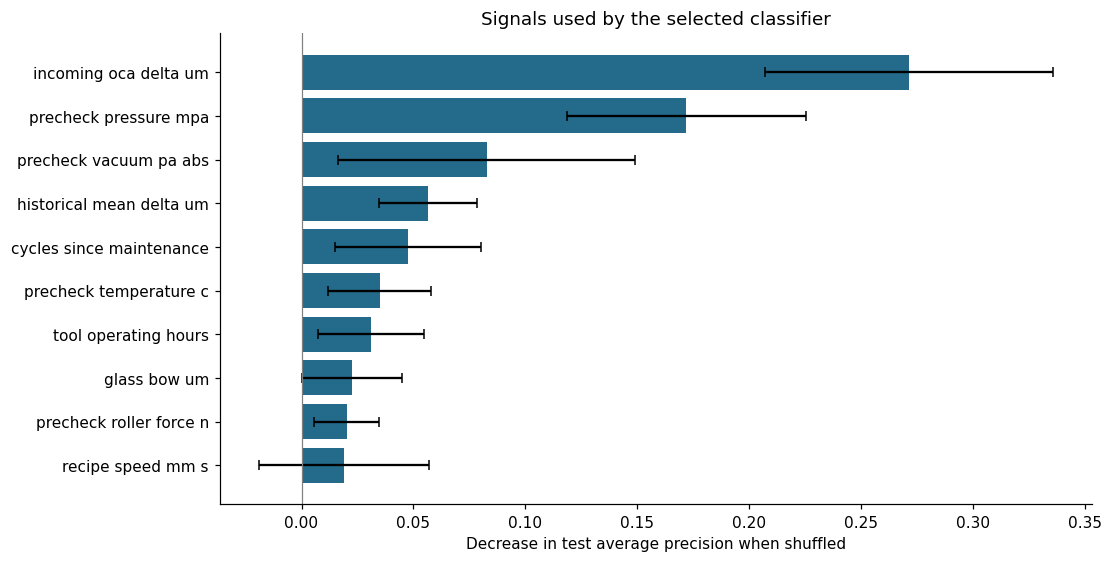

,feature,mean_ap_decrease,shuffle_sd
2,incoming_oca_delta_um,0.2714,0.0643
6,precheck_pressure_mpa,0.1719,0.0535
7,precheck_vacuum_pa_abs,0.0828,0.0664
14,historical_mean_delta_um,0.0565,0.0220
12,cycles_since_maintenance,0.0476,0.0325
5,precheck_temperature_c,0.0350,0.0230
13,tool_operating_hours,0.0309,0.0238
4,glass_bow_um,0.0226,0.0223
8,precheck_roller_force_n,0.0201,0.0146
9,recipe_speed_mm_s,0.0191,0.0379


In [28]:
importance = permutation_importance(winner,X_test,y_test,scoring='average_precision',
                                    n_repeats=20,random_state=SEED+2,n_jobs=1)
importance_table = pd.DataFrame({'feature':FEATURES,'mean_ap_decrease':importance.importances_mean,
                                 'shuffle_sd':importance.importances_std})
importance_table = importance_table.sort_values('mean_ap_decrease',ascending=False)
importance_table.to_csv(RESULTS/'permutation_importance.csv',index=False)
top = importance_table.head(10).iloc[::-1]
fig,ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax.barh(top.feature.str.replace('_',' '),top.mean_ap_decrease,xerr=top.shuffle_sd,
        color=BLUE,capsize=3)
ax.axvline(0,color='gray',linewidth=0.8)
ax.set(xlabel='Decrease in test average precision when shuffled',
       title='Signals used by the selected classifier')
fig.savefig(FIGURES/'feature_importance.png',dpi=160)
plt.show()
display(importance_table.head(10).round(4))

## 8. Findings for manufacturing and operations readers

The following summary is generated from the actual executed results. Each alert means a lot merits review. The model does not identify a validated recipe adjustment or quantify a guaranteed yield improvement.

In [29]:
top_features = importance_table.head(3).feature.str.replace('_',' ').tolist()
status = 'met' if met_success else 'not met'
findings = f"""### Later-period results

The selected **{winner_name}** model flagged **{result['tp']} of {int(y_test.sum())}** out-of-spec lots and missed **{result['fn']}**. It also flagged **{result['fp']} of {result['tn']+result['fp']}** acceptable lots. That gives **{result['recall']:.1%} recall**, **{result['false_positive_rate']:.1%} false-positive rate**, and **{result['precision']:.1%} precision**. The stated success criterion was **{status}** on this synthetic test.

### Operational meaning

Reviewing all **{int(prediction.sum())}** alerts would identify **{result['tp']}** out-of-spec lots in the 120-lot test period. **{result['fp']}** alerts would consume review capacity on acceptable lots. Each lot contains 50 units, but this lot-mean target does not support counting all units in a flagged lot as defective or rescued.

The largest importance scores belonged to **{', '.join(top_features)}**. Those rankings reflect the simulator and this fitted model. Correlated settings and the small test sample limit how precisely the signals can be ranked.

### Limits and next steps

The test contains only **{int(y_test.sum())}** positive lots. The five-day block-bootstrap recall interval is **{intervals.loc['recall','lower_95']:.1%}–{intervals.loc['recall','upper_95']:.1%}**. Longer production histories and repeated runs under different process assumptions are needed to assess stability.

Before operational use, collect timestamped pre-lot checks, incoming material measurements, metrology release times, and the actual disposition rule. Confirm measurement repeatability and product specifications. Validate on a later real production period, then test inspection prioritization in shadow mode. Maintenance and recipe decisions need engineering approval and controlled experiments. This exercise provides no measured factory savings.
"""
display(Markdown(findings))
(RESULTS/'nontechnical_findings.md').write_text('# Synthetic capstone findings\n\n'+findings+'\n')
print('Saved figures, predictions, grid-search tables, metrics, split audit, and findings.')

### Later-period results

The selected **Random forest** model flagged **8 of 12** out-of-spec lots and missed **4**. It also flagged **20 of 108** acceptable lots. That gives **66.7% recall**, **18.5% false-positive rate**, and **28.6% precision**. The stated success criterion was **not met** on this synthetic test.

### Operational meaning

Reviewing all **28** alerts would identify **8** out-of-spec lots in the 120-lot test period. **20** alerts would consume review capacity on acceptable lots. Each lot contains 50 units, but this lot-mean target does not support counting all units in a flagged lot as defective or rescued.

The largest importance scores belonged to **incoming oca delta um, precheck pressure mpa, precheck vacuum pa abs**. Those rankings reflect the simulator and this fitted model. Correlated settings and the small test sample limit how precisely the signals can be ranked.

### Limits and next steps

The test contains only **12** positive lots. The five-day block-bootstrap recall interval is **40.0%–90.0%**. Longer production histories and repeated runs under different process assumptions are needed to assess stability.

Before operational use, collect timestamped pre-lot checks, incoming material measurements, metrology release times, and the actual disposition rule. Confirm measurement repeatability and product specifications. Validate on a later real production period, then test inspection prioritization in shadow mode. Maintenance and recipe decisions need engineering approval and controlled experiments. This exercise provides no measured factory savings.


Saved figures, predictions, grid-search tables, metrics, split audit, and findings.


## 9. Rubric coverage and references

| Grading area | Evidence in this project |
|---|---|
| Project organization | README, linked executed notebook, data dictionary, data and results folders |
| Syntax and code quality | Executed cells, deterministic regeneration, integrity and timing assertions |
| Modeling | Dummy baseline, three classifiers, four time-aware folds, GridSearchCV, fixed threshold |
| Visualization | Training distributions, tool rates, material relationships, maintenance history, correlations, model comparison, threshold tradeoff, confusion matrix, precision–recall curve, importance |
| Findings | Plain-language counts, success criterion, uncertainty, operational implications, limitations and next steps |

Both supplied example capstone ZIP files were accessible and reviewed for organization, EDA, model comparison, interpretation, and README reporting. The assignment and rubric images were also reviewed. This project uses original synthetic lamination data and a chronological evaluation design.

The validation design follows the principles described in scikit-learn's [data leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html) and [TimeSeriesSplit documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).

Pressure and vacuum scales were informed by [3M's OCA 817X public technical sheet](https://multimedia.3m.com/mws/media/1775425O/3m-optically-clear-adhesive-oca-817x-series.pdf). All numerical process-response coefficients and acceptance limits remain fictional assumptions.